Features:
RETRIEVAL FROM TTNN
----
two_tower_score
two_tower_rank
two_tower_score_z
DONE

USER
----
user_rating_mean
user_rating_std
user_rating_count
DONE


MOVIE
-----
runtime (TMDB)
popularity (TMDB)
release_year - DONE
vote_count (TMDB)



USER × MOVIE
------------
genre_affinity - DONE
decade_affinity - DONE 
'Original_Language_affinity', 'Origin_country_affinity', 'Director_affinity', 'Top_cast_affinity', 'Keyword_affinity', 'Overview_affinity', 'Production_company_affinity', 'vote_count_affinity', 'vote_average_affinity', 'revenue_affinity'

In [1]:
import numpy as np
import pandas as pd
from xgboost import XGBRanker
import xgboost as xgb
from sklearn.metrics import ndcg_score

In [2]:
# from recommender script 
train_candidate_preds_ranked  = pd.read_parquet("../data/train_candidate_preds_ranked.parquet")
test_candidate_preds_ranked  = pd.read_parquet("../data/test_candidate_preds_ranked.parquet")

# should be using difference from user avg for numerical features 

# ['userId', 'movieId', 'rating', 'user_avg_rating', 'user_std_rating', 'user_count_rating', 'movie_Release_Year', 'genre_affinity', 'decade_affinity', 'predicted_rating', 'user_rank', 'z_score', 'Original_Language_affinity', 'Origin_country_affinity', 'Director_affinity', 'Top_cast_affinity', 'Keyword_affinity', 'Overview_affinity', 'Production_company_affinity', 'vote_count_affinity', 'vote_average_affinity', 'revenue_affinity']]

In [3]:


print(train_candidate_preds_ranked.columns.tolist())
print("cf_pred exists:", "cf_pred" in train_candidate_preds_ranked.columns)

['userId', 'movieId', 'tmdbId', 'rating', 'user_avg_rating', 'user_std_rating', 'user_count_rating', 'movie_Release_Year', 'genre_affinity', 'decade_affinity', 'Original_Language_affinity', 'Origin_country_affinity', 'Director_affinity', 'Top_cast_affinity', 'Keyword_affinity', 'Overview_affinity', 'Production_company_affinity', 'vote_count_affinity', 'vote_average_affinity', 'revenue_affinity', 'svd_affinity', 'predicted_rating', 'user_rank', 'z_score', 'cf_pred']
cf_pred exists: True


In [4]:
# Keep the per-user rows contiguous for XGBRanker's qid groups.
train_df = train_candidate_preds_ranked.sort_values(["userId"]).reset_index(drop=True)
test_df = test_candidate_preds_ranked.sort_values(["userId", "user_rank"]).reset_index(drop=True)
feature_columns = [
    "user_avg_rating", "user_std_rating", "user_count_rating",
    "movie_Release_Year", 
    "genre_affinity", 
    "decade_affinity",
    "predicted_rating", "user_rank", 
    "z_score", 
    "Original_Language_affinity", 
    "Origin_country_affinity",
    #"Director_affinity", 
    #"Top_cast_affinity", 
    #"Keyword_affinity", 
    #"Overview_affinity",
    #"Production_company_affinity", 
    #"vote_count_affinity", 
    #"vote_average_affinity", 
    #"revenue_affinity",
    "svd_affinity",
    "cf_pred"
]
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

def z_to_relevance(z):
    if z > 1:
        return 3
    elif z > 0.5:
        return 2
    elif z > 0:
        return 1
    return 0

z_train = (train_df["rating"] - train_df["user_avg_rating"]) / train_df["user_std_rating"]
train_df["relevance"] = z_train.apply(z_to_relevance)
z_test = (test_df["rating"] - test_df["user_avg_rating"]) / test_df["user_std_rating"]
test_df["relevance"] = z_test.apply(z_to_relevance)


In [5]:
ranker_params = dict(
    objective="rank:ndcg",
    eval_metric="ndcg@10",

    n_estimators=100,
    learning_rate=0.02,
    max_depth=2,
    min_child_weight=50,

    subsample=0.6,
    colsample_bytree=0.6,

    reg_lambda=100,
    reg_alpha=10,
    gamma=5,

    max_delta_step=1,

    random_state=42,
    tree_method="hist"
)

#ranker_params = dict(
#    objective="rank:ndcg", eval_metric="ndcg@10",
#    n_estimators=100, random_state=42
#)

model = xgb.XGBRanker(**ranker_params)
model.fit(X_train, train_df["relevance"], qid=train_df["userId"])
test_df["xgb_score"] = model.predict(X_test)
train_df["xgb_score"] = model.predict(X_train)
model.save_model("../models/xgboostranker_model.json")

test_df["xgb_rank"] = test_df.groupby("userId")["xgb_score"].rank(method="first", ascending=False)


In [6]:
# Compare mean per-user NDCG@10 on the same held-out groups.
for name, df in [("Train", train_df), ("Test", test_df)]:
    user_ndcgs = []
    for _, user_data in df.groupby("userId"):
        relevance = user_data["relevance"].to_numpy().reshape(1, -1)
        user_ndcgs.append(ndcg_score(
            relevance, user_data["xgb_score"].to_numpy().reshape(1, -1), k=10
        ))
    print(f"NDCG@10={np.mean(user_ndcgs):.4f}")


NDCG@10=0.7628
NDCG@10=0.6690


In [ ]:
# NDCG@10 = 0.493 w all TMDB enriched features
# director affinity heavily overfits therefore exclude
# cast affinity is a strong signal, but also overfits, therefore exclude
# keyword affinity is a strong signal, but also overfits, therefore exclude
# overview affinity NDCG@10 = 0.6098 (still overfit)
# production company affinity overfit
# 0.6169 wo TMDB
# 0.6192 svd affinity
# 0.6690 collab filter

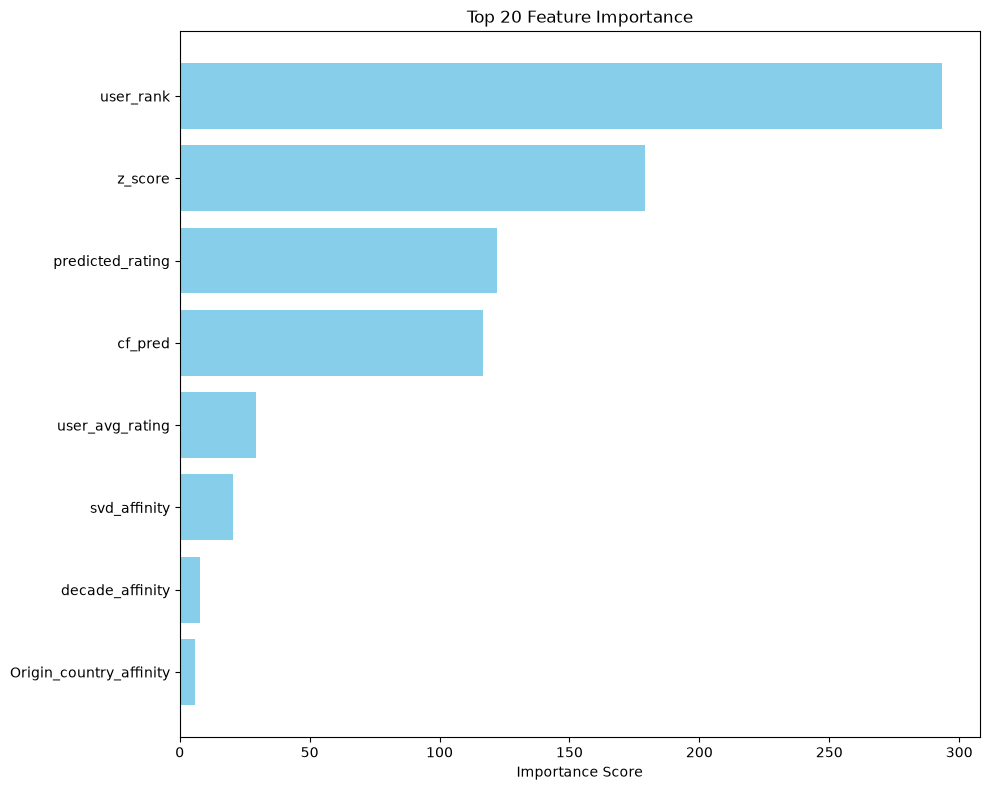

In [8]:
#feature importance vis
import matplotlib.pyplot as plt

importance = model.get_booster().get_score(importance_type='gain')

importance_df = pd.DataFrame({
    'Feature': list(importance.keys()),
    'Importance': list(importance.values())
}).sort_values(by='Importance', ascending=False)

top_n = 20
plt.figure(figsize=(10, 8))
plt.barh(
    importance_df['Feature'].head(top_n)[::-1],
    importance_df['Importance'].head(top_n)[::-1],
    color='skyblue'
)
plt.xlabel('Importance Score')
plt.title(f'Top {top_n} Feature Importance')
plt.tight_layout()
plt.show()